In [45]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

In [46]:
# generation of example organic molecule graphs
ELEMENTS = ['C', 'O', 'N']
MIN_ATOMS = 10
MAX_ATOMS = 15
ORDERS = {
    'C': 4,
    'O': 2,
    'N': 3
}

START_ELEM = 'C'

NODE_COLORS = {
    'C': 'grey',
    'O': 'red',
    'N': 'green'
}

def add_node_to_graph(graph, node_id, element, bond_order):
    if graph.nodes[node_id]['order'] - bond_order < 0:
        return None

    new_node_id = len(graph.nodes)
    graph.add_node(new_node_id, element=element, order=ORDERS[element]-bond_order)
    graph.add_edge(node_id, new_node_id, bond_order=bond_order)
    graph.nodes[node_id]['order'] -= bond_order
    return new_node_id


[0, 1]


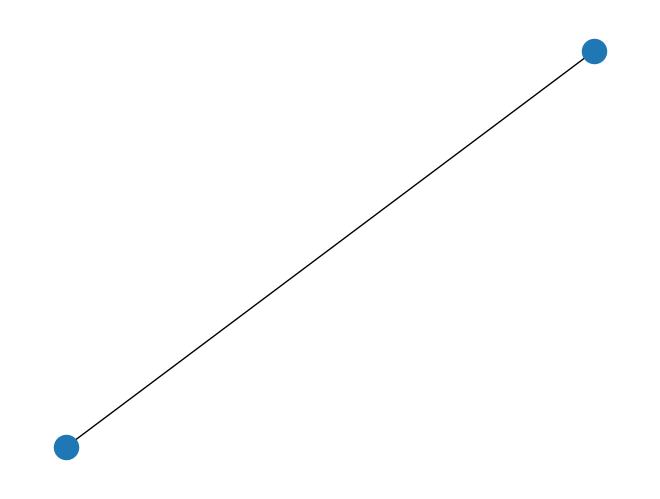

In [47]:
# add_node_to_graph function test
ex_graph = nx.Graph()
ex_graph.add_node(0, element=START_ELEM, order=ORDERS[START_ELEM])
if add_node_to_graph(ex_graph, 0, 'C', 2):
    print(ex_graph.nodes)
    nx.draw(ex_graph)

In [48]:
def generate_graph(num_atoms):
    graph = nx.Graph()
    graph.add_node(0, element=START_ELEM, order=ORDERS[START_ELEM])
    atom_added = 0
    while atom_added < num_atoms:
        node_id = np.random.randint(len(graph.nodes))
        element = np.random.choice(ELEMENTS)
        max_bond_order = min(ORDERS[element], graph.nodes[node_id]['order'])
        if max_bond_order == 0:
            continue
        bond_order = np.random.randint(1, ORDERS[element])
        new_node_id = add_node_to_graph(graph, node_id, element, bond_order)
        if new_node_id is not None:
            atom_added += 1
    return graph

In [49]:
def draw_molecule_graph(graph):
    graph_pos = nx.spring_layout(graph)
    nx.draw_networkx_nodes(graph, graph_pos, node_color=[NODE_COLORS[graph.nodes[i]['element']] for i in graph.nodes])
    # drawing edges: edge lines = bond order
    edge_widths = [graph.edges[edge]['bond_order'] * 3 for edge in graph.edges]
    nx.draw_networkx_edges(graph, graph_pos, width=edge_widths, edge_color='gray')
    # drawing labels
    nx.draw_networkx_labels(graph, graph_pos)
    plt.show()

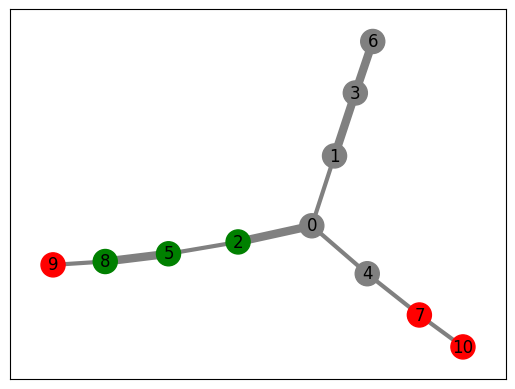

In [50]:
mg = generate_graph(10)
draw_molecule_graph(mg)

In [66]:
# basic non-shared electron-pairs
ED = {
    'C': 0,
    'O': 2,
    'N': 1
}

# eletronegativity
EN = {
    'C': 2.55,
    'O': 3.44,
    'N': 3.04
}

def generate_proton_affinity(graph):
    # node[el_density] = node[electronegativity] - mean(neighbor[electronegativity])
    # node[PA] = C*node[el_density]

    updates = {}
    for n in graph.nodes:
        graph.nodes[n]['el_density'] = (EN[graph.nodes[n]['element']] - np.mean([EN[graph.nodes[nbr]['element']] for nbr in graph.neighbors(n)]))**2


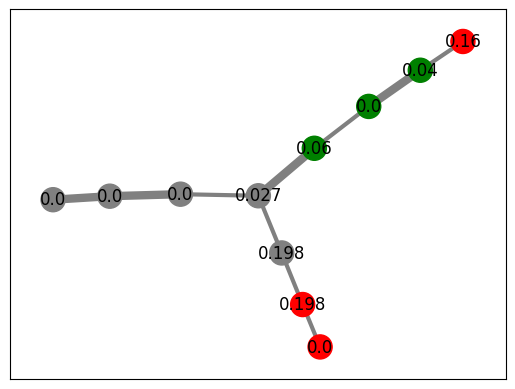

In [67]:
def draw_molecule_graph(graph, el_density=False):
    graph_pos = nx.spring_layout(graph)
    nx.draw_networkx_nodes(graph, graph_pos, node_color=[NODE_COLORS[graph.nodes[i]['element']] for i in graph.nodes])
    # drawing edges: edge lines = bond order
    edge_widths = [graph.edges[edge]['bond_order'] * 3 for edge in graph.edges]
    nx.draw_networkx_edges(graph, graph_pos, width=edge_widths, edge_color='gray')
    if el_density:
        nx.draw_networkx_labels(graph, graph_pos, labels={n: round(graph.nodes[n]['el_density'], 3) for n in graph.nodes})
    # drawing labels
    # nx.draw_networkx_labels(graph, graph_pos)
    plt.show()

generate_proton_affinity(mg)
draw_molecule_graph(mg, el_density=True)

In [68]:
# generate molecule dataset
def generate_dataset(num_molecules):
    molecules = []
    for i in range(num_molecules):
        num_atoms = np.random.randint(MIN_ATOMS, MAX_ATOMS)
        graph = generate_graph(num_atoms)
        generate_proton_affinity(graph)
        molecules.append(graph)

    return molecules

molecule_set = generate_dataset(300)

In [69]:
rand_idx = np.random.permutation(len(molecule_set))
train_idx = rand_idx[:int(0.8*len(molecule_set))]
test_idx = rand_idx[int(0.8*len(molecule_set)):]
train_set = [molecule_set[i] for i in train_idx]
test_set = [molecule_set[i] for i in test_idx]

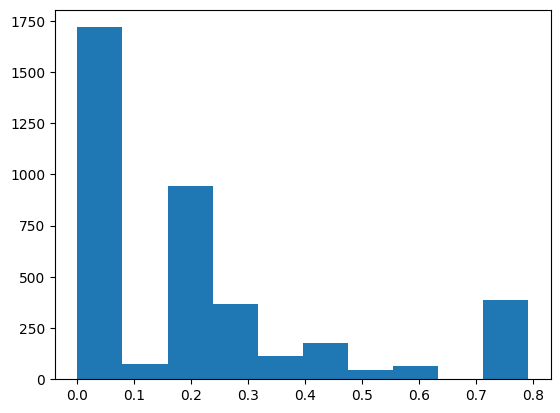

In [70]:
# el_density distribution of molecule_set(histogram)
elds = []
for molecule in molecule_set:
    elds += [molecule.nodes[i]['el_density'] for i in molecule.nodes]

plt.hist(elds)
plt.show()

In [83]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# 원소를 ID로 매핑하기 위한 딕셔너리
ELEM_TO_IDX = {'C': 0, 'O': 1, 'N': 2}
NUM_ELEMENTS = len(ELEM_TO_IDX)

class MoleculeGNN(nn.Module):
    def __init__(self, hidden_dim=16):
        super(MoleculeGNN, self).__init__()
        # 원소 원-핫 인코딩(3차원) + H수(degree, 1차원) = 4차원 입력
        input_dim = NUM_ELEMENTS + 1

        # 노드 특징 변환용 선형 레이어
        self.node_encoder = nn.Linear(input_dim, hidden_dim)

        # 1회 메시지 패싱을 위한 Message Passing Layer
        # 이웃의 특징들의 평균을 계산한 뒤 선형 변환하여 더해줍니다.
        self.msg_fc = nn.Linear(hidden_dim, hidden_dim)
        self.update_fc = nn.Linear(hidden_dim, hidden_dim)

        # 최종 전자 밀도(Scalar) 예측을 위한 출력 레이어
        self.predictor = nn.Linear(hidden_dim, 1)

    def forward(self, x, adj):
        # x: [num_nodes, input_dim]
        # adj: [num_nodes, num_nodes] (인접 행렬)

        # 1. 초기 노드 임베딩
        h = (self.node_encoder(x))

        # 2. 1회 메시지 패싱 (Message Passing)
        # 이웃 노드의 임베딩을 평균내어 수집 (인접 행렬과 노드 임베딩의 행렬곱 이용)
        # 차수(degree) 분모로 정규화
        deg = adj.sum(dim=1, keepdim=True).clamp(min=1)
        neighbor_agg = torch.matmul(adj, h) / deg

        # 메시지 업데이트
        msg = F.relu(self.msg_fc(neighbor_agg))
        h = F.relu(self.update_fc(h) + msg)

        # 3. 예측값 산출
        out = self.predictor(h).squeeze(-1) # [num_nodes]
        return out

In [84]:
def prepare_data(graph):
    """
    NetworkX 그래프를 GNN 입력에 맞게 PyTorch Tensor로 변환하는 함수입니다.
    - x (노드 특징): 원소 원-핫 인코딩(3차원) + 중원자 수(degree, 1차원) = 4차원
    - adj (인접 행렬): [num_nodes, num_nodes]
    - y (타겟): 각 노드의 'el_density' 값
    """
    num_nodes = len(graph.nodes)

    # 1. 노드 특징 (x) 구축
    x_list = []
    for i in range(num_nodes):
        node_attr = graph.nodes[i]
        # 원소 원-핫 인코딩
        elem_one_hot = [0.0] * NUM_ELEMENTS
        elem_idx = ELEM_TO_IDX[node_attr['element']]
        elem_one_hot[elem_idx] = 1.0

        # 결합된 중원자 수 (Degree)
        degree = float(graph.degree(i))

        node_feat = elem_one_hot + [degree]
        x_list.append(node_feat)

    x = torch.tensor(x_list, dtype=torch.float32)

    # 2. 인접 행렬 (adj) 구축
    adj = nx.adjacency_matrix(graph).todense()
    adj = torch.tensor(adj, dtype=torch.float32)

    # 3. 타겟값 (y) 구축
    y = torch.tensor([graph.nodes[i]['el_density'] for i in range(num_nodes)], dtype=torch.float32)

    return x, adj, y

In [85]:
# 모델 초기화
model = MoleculeGNN(hidden_dim=32)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

# 에폭 수 설정
epochs = 100
train_losses = []
test_losses = []

# 학습 루프
for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for graph in train_set:
        optimizer.zero_grad()

        x, adj, y = prepare_data(graph)

        # 예측 및 손실 계산
        pred = model(x, adj)
        loss = criterion(pred, y)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_set)
    train_losses.append(avg_train_loss)

    # 검증/테스트 루프
    model.eval()
    epoch_test_loss = 0.0
    with torch.no_grad():
        for graph in test_set:
            x, adj, y = prepare_data(graph)
            pred = model(x, adj)
            loss = criterion(pred, y)
            epoch_test_loss += loss.item()

    avg_test_loss = epoch_test_loss / len(test_set)
    test_losses.append(avg_test_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:03d}/{epochs} | Train MSE: {avg_train_loss:.6f} | Test MSE: {avg_test_loss:.6f}")

Epoch 010/100 | Train MSE: 0.000070 | Test MSE: 0.000046
Epoch 020/100 | Train MSE: 0.000153 | Test MSE: 0.000041
Epoch 030/100 | Train MSE: 0.000112 | Test MSE: 0.000040
Epoch 040/100 | Train MSE: 0.000164 | Test MSE: 0.000065
Epoch 050/100 | Train MSE: 0.000182 | Test MSE: 0.000042
Epoch 060/100 | Train MSE: 0.000160 | Test MSE: 0.000069
Epoch 070/100 | Train MSE: 0.000156 | Test MSE: 0.000075
Epoch 080/100 | Train MSE: 0.000190 | Test MSE: 0.000079
Epoch 090/100 | Train MSE: 0.000148 | Test MSE: 0.000081
Epoch 100/100 | Train MSE: 0.000232 | Test MSE: 0.000081


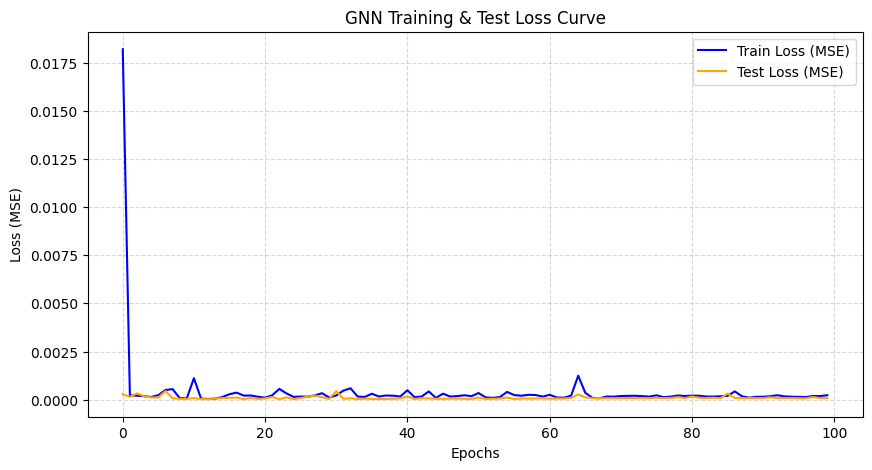

In [86]:
# 학습 곡선 (Loss Curve) 시각화
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss (MSE)', color='blue')
plt.plot(test_losses, label='Test Loss (MSE)', color='orange')
plt.title('GNN Training & Test Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [109]:
ts_last = prepare_data(test_set[-3])

In [110]:
ts_last_pred = model(ts_last[0], ts_last[1])

In [111]:
ts_last_target = ts_last[-1]

In [112]:
np.abs((ts_last_pred-ts_last_target).detach().numpy())

array([0.01060551, 0.00226514, 0.00817376, 0.00764179, 0.00024014,
       0.00633749, 0.00015426, 0.00024014, 0.01425882, 0.00040719,
       0.00024014, 0.00226514, 0.00648741], dtype=float32)

In [91]:
ts_last_pred

tensor([ 3.7672e-01,  2.0489e-01,  4.8712e-02,  2.4574e-02,  1.5730e-01,
        -2.4014e-04, -2.4014e-04,  2.4574e-02,  2.5741e-02,  1.6649e-01,
         1.6649e-01], grad_fn=<SqueezeBackward1>)

In [92]:
ts_last_target

tensor([0.3885, 0.1980, 0.0600, 0.0400, 0.1600, 0.0000, 0.0020, 0.0400, 0.0400,
        0.1600, 0.1600])